## Machine Learning: Modelo Supervisado No 1. El Modelo de Regresion

### Andrés Eduardo Rangel Jiménez


- Economista `(Universidad del Valle, Colombia)`

- MSc en Econometria `(Universidad Torcuato Di Tella, Argentina)`

- PhD en Dirección de Empresas `(Universidad de Valencia, España)`

#### Bases de datos utilizadas:

- `cerveza.dta`
- `Marketing_Data`
- `Walmart`

## Paso inicial:  Importamos las librerías de la clase
```

Con el objetivo de tener un notebook ordenado, usualmente en analitica y ciencia de datos se acostumbra a importar todas las librerías al inicio

In [684]:
import pandas as pd
import numpy as np
import re
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import OneHotEncoder
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from statsmodels.stats.diagnostic import acorr_breusch_godfrey
from statsmodels.stats.diagnostic import het_white

## 1. Modelo de regresion lineal multiple (RLM). Una introducción

In [2]:
from IPython.display import HTML, display

with open("Regresion_lineal_didactico.html", "r", encoding="utf-8") as f:
    html_content = f.read()

display(HTML(html_content))

## 1. Modelo de regresion lineal multiple (RLM). Una introducción


El modelo de regresión lineal tiene alto poder explicativo de entre los algoritmos de las tecnicas de machine learning supervisado, si bien tiene bajo poder predictivo. El modelo de regresión parte del concepto de funcion:

$$
y=f(X)
$$

Supongamos que la matrix X tiene solo dos variables. Para nuestro ejercicio tenemos que la matrix X esta compuesta de dos variables $X_1$ y $X_2$. En este caso podemos decir que la variable $y$ (variable dependiente) esta en funcion o depende (por eso la llamamos variable dependiente) de las variables $X_1$ y $X_2$, variables explicativas.

Pero contextualicemos esto un poco mas:  Comencemos con una pregunta de investigación, tiene logica comenzar con esto no?...al fin y al cabo los modelos de analitica sirven para responder a preguntas de investigación. 

Supongamos que algo de la realidad nos interesa, estudiar los salarios. De que dependen la demanda de un bien?. La teoria economica nos dices que la demanda depende (entre otras varaibles, pero solo detengamonos en dos) del precio del bien  y del ingreso. Pero como vamos a usar modelos estadisticos (es lo que es machine learnign en el fondo, de hecho yendo mas alla, toda la IA es estadistica avanzada), necesitamos usar lenguaje matematico. Comencemos con "bautizar" las variables:


$$
y= Cantidad demandada del bien (unidades)
$$

$$
X_1= Precio (dolares)
$$

$$
X_2= Ingreso (dolares)
$$

Dijimos que la teoria economica señala que  los salarios dependen de la educacion y la experiencia
$$
y=f(X_1, X_2)
$$



Pero la funcion anterior no nos especifica si la relación entre cada una de las variables que componen X es de naturaleza directa o inversa.   Solo el concepto matematico de derivada parcial no puede decir la naturaleza de la relación:

Cuando aumenta el precio, la cantidad demandada disminuye (relaciona inversa  entre $Y$ y $X_1$

$$
\frac{\partial y}{\partial X_1}<0 
$$

Cuando aumenta el ingreso, la cantidad demandada aumenta (relaciona directa entre $Y$ y $X_2$

$$
\frac{\partial y}{\partial X_2}>0 
$$

Si la derivada es positiva, la relación entre la variable dependiente $y$ y la variable explicativa $X_1$ es directa, es decir si la variable explicativa aumenta la variable dependiente aumenta. Si la derivada es negativa, la relación entre la variable dependiente $y$ y la variable explicativa $X_1$ es inversa, es decir si la variable explicativa aumenta (disminuye) la variable dependiente disminuye (aumenta). 


Pasemos ahora a la especificacion del modelo de regresión:

Ecuación 1:
$$
Y_i=\beta_0+\beta_1X_{1i}+\beta_2X_{2i}+u_i\quad \text{(Ecuación 1)}
$$

Miremos los componentes del modelo de regresión:

- La variable $y$ la denominamos regresor o variable dependiente.
- las variables $X_1$ y $X_2$ son denominadas variables explicativas o regresores.
- $u_i$ es el termino de errror del modelo. Este termino de error hace compatible la realidad con la teoria. Porque?.  Recordemos que  una teoría es un conjunto organizado de ideas, principios o explicaciones que buscan describir, entender o predecir un fenómeno. Sin embargo ninguna teoria explica perfectamente la realidad. En este caso $u_i$ es la distancia entre la realidad que estudiamos $y$ y la teoria que son las variables $X$. Recordemos que las variables que incluyo en el modelo der regresion hacen alusión a la teoria o al estado del arte que sobre el problema de investigacion se haya escrito.
- $beta_k$ son denominados parametros (poblacionales y desconocidos). Sobre estos parametros podemos hacer una clasificacion: $beta_0$ es el intercepto del modelo y $beta_1$ y $beta_2$ las pendientes del modelo.  Son las pendientes del modelo las que me indican la relación entre la variable dependiente y las variables explicativas. En realidad las pendientes son las derivadas parciales que especificamos mas arriba:

$$
\beta_1=\frac{\partial y}{\partial X_1}
$$

$$
\beta_2=\frac{\partial y}{\partial X_2}
$$

Regresando al termino de error, podemos ver que $u_i$ es la distancia entre la realidad que queremos estudiar, en este caso nuestra variable dependiente o variable objetivo $Y_i$ y $(\beta_0+\beta_1X_{1i}+\beta_2X_{2i})$ que es la teoria. 

$$
u_i=Y_i-(\beta_0+\beta_1X_{1i}+\beta_2X_{2i})\quad \text{(Ecuación 2)}
$$

Venimos de un modelo teorico:

$$
Y_i=\beta_0+\beta_1X_{1i}+\beta_2X_{2i}+u_i
$$

No conocemos los parametros y por eso necesitamos estimarlos y obtener este modelo:


$$
Y_i = \hat{\beta}_0 + \hat{\beta}_1 X_{1i} + \hat{\beta}_2 X_{2i} + \hat{u}_i \quad \text{(Ecuación 3)}
$$

Para obtener los estimadores (los beta hat o beta "sombrero") utilizo una información muestral de las variables explicativas y dependiente.  Utilizamos un metodo denominado Minimos Cuadrados Ordinarios (Ordinary Least Squared, OLS). Mas alla de explicar la matematica para llegar a la formula que se obtiene aplicando herramientas de algebra matricial, lo importante es entender la intuicion del metodo. De la ecuación 2 vemos que el objetivo de cualquier campo de las ciencias es minimizar la distancia entre la realidad que estudiamos (variable dependiente u objetivo $Y$) y la teoria.  Entonces deseamos minimizar el termino de error.   De esto se trata el metodo OLS, de encontrar los estimadores que minimizan estos residuos (en realidad el metodo minimiza la suma de los cuadrados de residuos pero por ahora no nos compliquemos con estos tecnicismos).

A continuacion abordemos un problema de investigación.  Como impactan los diferentes canales de publicidad a las ventas de una empresa.

Es muy imporante saber en que medida estan las variables, pues de esta manera es posible interpretar los estimadores.

## Inferencia estadistica.
## Inferencia estadistica individual

La inferencia estadistica individual nos sirve para saber que variables son estadisticamente significativas, es decir, si la variable es relevante al momento de explicar la variable dependiente. Si bien se puede hacer inferencia estadistica individual mediantes tres metodos: estadigrafo t (utilizando la distribución teorica t-student), intervalo de confianza y por ulitmo nivel de probabilidad.  Vamos a utilizar este ultimo.

Lo primero que vamos a hacer cuando realizamos inferencia estadistica es plantear una hipoteiss nula y alterna.  Si nos preguntamos si la variable pb es significativa estadisticamente, planteamos el siguietne sistema de hipotesis:


$$
H_0: \beta_1=0
$$
$$
\\H_A: \beta_1\neq0
$$


La hipotesis nula significa que la variable explicativa asociada a $\beta_1$ no es significativa estadisticamente significativa o no es relevante para explicar a la variable dependiente.  Por otro lado la hipotesis alterna significa que la variable es estadisticamente significativa o que la variable explicativa es relevante para explicar a la variable dependiente. Se plantea el otro sistema de hipotesis para $\beta_2$.

$$
H_0: \beta_2=0
$$
$$
\\H_A: \beta_2\neq0
$$


La regla de decision para rechazar o no rechazar la hipotesis nula es la siguiente: 

Utilizamos el valor del nivel de probabilidad (P>|t|)  en la salida de regresion). Le llamare nivel de probabildad o P>|t|.
Si el nivel de probabilidad es menor a 0.05, se rechaza la hipotesis nula, y concluimos que la variable explicativa es significativa, es decir la variable es relevante para explicar a la variable target o dependiente.

Por otro lado si el nivel de probabilidad es mayor que 0.05, no rechazamos la hipotesis nula y concluimos que la variable explicativa es no significativa, es decir no es relevante para explicar a la variable dependiente.


En este caso, ambas hipotesis nulas son rechazadas. En el primer caso el nivel de probablidad (0.003) es menor a 0.05. En consecuencia  se rechaza Ho y la variable pb es estadisticamente significativa (relevante para explicar a q).  En el segundo sistema de hipotesis la hipotesis nula es rechazada también pues el nivel de probabilidad (0.040) es menor que 0.05.  En este caso rechazamos la hipoteis nula del segundo sistema y la variable m es estadisticamente significativa (es decir la variable m es relevante para explicar a la variable dependiente q).


## Inferencia estadistica global

Hagamos inferencia estadistica global o en conjunto. Planteemos las hipotesis: 

$$
H_0: \beta_1=\beta_2=0
$$
$$
\\H_A: Al~menos~un~\beta_k\neq0, 
$$

La hipotesis nula significa que las variables en su conjunto no son significativas. La hipotesis alterna (que resutals de falsear la hipotesis nula) nos dice que las variables en su conjunto si son significativas. La regla de decision es la siguiente: 

- Si el nivel de probabilidad,  Prob (F-statistic), es menor que 0.05 rechazamos la hipotesis nula. Si el nivel de probabilidad es mayor que 0.05 luego no rechazamos la hipotesis nula. En este caso el nivel de probabilidad (5.11e-05) es menor que 0.05, por lo que rechazamos la hipotesis nula, esto es las variables explicativas en su conjunto (pb y m) son significativas en su conjunto, esto es son relevantes en su conjunto al momento de explicar a la variable dependiente.

##  Coeficiente de bondad de ajuste
```

El coeficiente de bondad de ajuste indica el poder explicativo del modelo.

 

El R cuadrado indica que el modelo explica a la variable dependiente.

Sin entrar a la minucia matematica del modelo, debe anotarse que en el numerador de la formula del R cuadrado, tenemos la suma de cuadrados explicada (SCE). Esta suma esta asociada al numero de variables explicativas. Lo anterior significa que la SCE aumenta cuando se ingresan mas variables al modelo sin importar si estas son estadisticamente significativas o no. La SCT es la suma de cuadrados totales y esta asociada a la variable dependiente. Cuando aumentan el numero de explicativas SCE aumenta pero no asi SCT.

De todo esto se desprende de que el SCE de un modelo multiple (con dos variables explicativas), sera mayor que el SCE de un modelo simple (con solo una variable explicativa) y en consecuencia su R cuadrado. El R cuadrado de un modelo con dos variables es superior al R cuadrado de un modelo con una variable.

Si yo necesito realizar una comparacion entre modelos con la misma variable dependiente y diferente numero de explicativas, no puedo utilizar el R cuadrado, debo utilizar el R cuadrado ajustado (Adj. R-squared). Uno escoge como mejor modelo el modelo que tiene el mayor R cuadrado ajustado.

In [ ]:
# Este codigo solo debe correrse en google colab
from google.colab import files

# Abrir ventana para seleccionar el archivo
uploaded = files.upload()

## Ejercicio 0

Vamos a modela una funcion de demanda

In [173]:
dtafile = 'cerveza.dta'
df0 = pd.read_stata(dtafile)
df0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   obs     30 non-null     object        
 1   q       30 non-null     float32       
 2   pb      30 non-null     float32       
 3   pl      30 non-null     float32       
 4   pr      30 non-null     float32       
 5   m       30 non-null     int32         
 6   t       30 non-null     datetime64[ns]
dtypes: datetime64[ns](1), float32(4), int32(1), object(1)
memory usage: 1.2+ KB


In [144]:
df0.head()

,obs,q,pb,pl,pr,m,t,lq,lpb,lm
0,01/01/60,81.699997,1.78,6.95,1.11,25088,1960-01-01,4.403054,0.576613,10.130145
1,01/01/61,56.900002,2.27,7.32,0.67,26561,1961-01-01,4.041296,0.819780,10.187199
2,01/01/62,64.099998,2.21,6.96,0.83,25510,1962-01-01,4.160444,0.792993,10.146826
3,01/01/63,65.400002,2.15,7.18,0.75,27158,1963-01-01,4.180522,0.765468,10.209427
4,01/01/64,64.099998,2.26,7.46,1.06,27162,1964-01-01,4.160444,0.815365,10.209574


## Creacion de variables
```
A continacion creare algunas variables en logaritmo natural pues las necesitare para estimar distintas especificaciones de modelos.

In [175]:
df0['lq'] = np.log(df0['q'])
df0['lpb'] = np.log(df0['pb'])
df0['lm'] = np.log(df0['m'])
df0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   obs     30 non-null     object        
 1   q       30 non-null     float32       
 2   pb      30 non-null     float32       
 3   pl      30 non-null     float32       
 4   pr      30 non-null     float32       
 5   m       30 non-null     int32         
 6   t       30 non-null     datetime64[ns]
 7   lq      30 non-null     float32       
 8   lpb     30 non-null     float32       
 9   lm      30 non-null     float64       
dtypes: datetime64[ns](1), float32(6), float64(1), int32(1), object(1)
memory usage: 1.7+ KB


## 1. Estimando la regresion con statsmodels (especificacion niveles-niveles)
```
La especificacion niveles-niveles significa que se trabajan con las unidades de medidas originales de las variables tanto en la dependiente (y) como en las explicativas (X)

Con statsmodels es la forma más completa para ver los resultados al estilo econométrico, pues summary() te da coeficientes, errores estándar, t-stats, p-values, R², etc.  La especificacion niveles-niveles significa que se trabajan con las unidades de medidas originales de las variables.

In [33]:
# Variables independiente
X = df0[['pb', 'm']]
X = sm.add_constant(X)  # agrega el intercepto

# Variable dependiente
y = df0['q']

In [35]:
X.head()

,const,pb,m
0,1.0,1.78,25088
1,1.0,2.27,26561
2,1.0,2.21,25510
3,1.0,2.15,27158
4,1.0,2.26,27162


In [37]:
# Estimar el modelo
modelo = sm.OLS(y, X).fit()

# Ver resultados
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                      q   R-squared:                       0.750
Model:                            OLS   Adj. R-squared:                  0.732
Method:                 Least Squares   F-statistic:                     40.57
Date:                Wed, 08 Apr 2026   Prob (F-statistic):           7.33e-09
Time:                        10:20:04   Log-Likelihood:                -83.090
No. Observations:                  30   AIC:                             172.2
Df Residuals:                      27   BIC:                             176.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         57.1599      9.468      6.037      0.0

Con la biblioteca de Machine Learning sklearn, no se obtienen resultados tan completos.

## 1.1  Intepretacion de coeficientes segun especificacion niveles-niveles

```

Cuando la variable dependiente esta en niveles  y la explicativa en niveles se interpreta asi de manera general: por una variación en una unidad de la variable X, la variable dependiente varia en una cuantia de unidades (equivalente al valor del estimador asociado)

pb = -27.6527
Aca el signo del estimador asociado a pb (negativo) nos dice que la relación entre la variable dependiente (q) y la explicativa (pb) es inversa
Por un incremento de un dolar en el precio de la cerveza (pb), la cantidad demandada de cerveza disminuye 27.6527 unidades, manteniendo el ingreso constante (clausula de ceteris paribus). 

m = 0.0026
Aca el signo del estimador asociado a m (positivo) nos dice que la relación entre la variable dependiente (q) y la explicativa (pb) es directa.
Por un incremento de un dolar en el ingreso (m), la cantidad demandada de cerveza aumenta  0.0026 unidades , manteniendo el precio  constante.


## 2. Estimando la regresion con statsmodels (especificacion logaritmo-niveles)
```
La especificacion logaritmo-niveles significa que la variable dependiente esta medida en logaritmo natural y las explicativas (X) en niveles

In [64]:
# Variables independientes
X = df0[['pb', 'm']]
X = sm.add_constant(X)  # agrega el intercepto

# Variable dependiente
y = df0['lq']

# Estimar el modelo
modelo = sm.OLS(y, X).fit()

# Ver resultados
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                     lq   R-squared:                       0.746
Model:                            OLS   Adj. R-squared:                  0.727
Method:                 Least Squares   F-statistic:                     39.60
Date:                Tue, 07 Apr 2026   Prob (F-statistic):           9.35e-09
Time:                        13:56:26   Log-Likelihood:                 38.946
No. Observations:                  30   AIC:                            -71.89
Df Residuals:                      27   BIC:                            -67.69
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.0637      0.162     25.080      0.0

## 2.1 Intepretacion de coeficientes segun  especificacion logaritmo(y)-niveles(X)
```
Cuando la variable dependiente esta en logaritmos y la explicativa en niveles se interpreta asi de manera general: por una variación  en una unidad de la variable X, la variable dependiente varia porcentualmente (en la cuantia que resulta de multiplicar el estimador por 100)

pb = -0.4544
Un aumento de 1 unidad (dolar) en el precio de la cerveza está asociado con una disminución de 45.44% (0.4544*100) en la cantidad demandada, manteniendo el ingreso constante.
La fórmula general es: el coeficiente × 100 = cambio porcentual en Q.
Este coeficiente es negativo, lo cual es consistente con la ley de la demanda: a mayor precio, menor cantidad demandada.

m = 4.154e-05
Un aumento de 1 unidad (dolar) en el ingreso está asociado con un aumento de 0.00415% (0.00004154*100) en la cantidad demandada. 

## 3. Estimando la regresion con statsmodels (especificacion:  logaritmo-logaritmo (natural))
```
La especificacion log-log significa que tanto la variable dependiente como las explicativas estan en terminos de logaritmo natural.

In [70]:
# Variables independientes
X = df0[['lpb', 'lm']]
X = sm.add_constant(X)  # agrega el intercepto

# Variable dependiente
y = df0['lq']

# Estimar el modelo
modelo = sm.OLS(y, X).fit()

# Ver resultados
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                     lq   R-squared:                       0.775
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     46.42
Date:                Tue, 07 Apr 2026   Prob (F-statistic):           1.83e-09
Time:                        15:02:40   Log-Likelihood:                 40.759
No. Observations:                  30   AIC:                            -75.52
Df Residuals:                      27   BIC:                            -71.31
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -6.6831      3.516     -1.901      0.0

## 3.1 Intepretacion de coeficientes segun  especificacion logaritmo(y)-logaritmos (X)
```
Cuando la variable dependiente esta en logaritmos y la explicativa en logartimos  se interpreta asi de manera general: por una variación en un 1% de  variable X, la variacion de la variable dependiente varia porcentualmente (en la cuantia que resulta de multiplicar el estimador por 100)

lpb = -1.2212
Por un incremento de 1% en el precio de la cerveza la cantidad demandada de cerveza disminuye en 1.22%, manteniendo el ingreso constante.

lm =  1.1604
Por un incremento de un 1% en el ingreso, la cantidad demandada de cerveza aumenta en 1.16%, manteniendo el precio constante.

## 4. Estimando la regresion con statsmodels (especificacion: niveles-logaritmo (natural))
```
La especificacion niveles-logaritmico significa que  la variable dependiente esta en niveles y las explicativas estan en terminos de logaritmo natural.


In [30]:
# Variables independientes
X = df0[['lpb', 'lm']]
X = sm.add_constant(X)  # agrega el intercepto

# Variable dependiente
y = df0['q']

# Estimar el modelo
modelo = sm.OLS(y, X).fit()

# Ver resultados
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                      q   R-squared:                       0.799
Model:                            OLS   Adj. R-squared:                  0.784
Method:                 Least Squares   F-statistic:                     53.61
Date:                Tue, 07 Apr 2026   Prob (F-statistic):           3.96e-10
Time:                        17:16:34   Log-Likelihood:                -79.849
No. Observations:                  30   AIC:                             165.7
Df Residuals:                      27   BIC:                             169.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -646.2969    195.914     -3.299      0.0

## 4.1 Intepretacion de coeficientes segun  especificacion logaritmo(y)-logaritmos (X)
```
Cuando la variable dependiente esta en niveles y la explicativa en logaritmos  se interpreta asi de manera general: por una variación en un 1% de  variable X, la variacion de la variable dependiente varia marginalmente, en un unidad (en Bk unidades)

lpb =  -76.6795 
Un aumento del 1% en el precio de la cerveza está asociado con una disminución de 0.7668 unidades en la cantidad demandada, manteniendo el ingreso constante.
(-76.68 / 100 = -0.7668)

lm =  75.7938
Un aumento del 1% en el ingreso está asociado con un aumento de 0.7579 unidades en la cantidad demandada, manteniendo el precio constante.
(75.79 / 100 = 0.7579)

##### Nota. Se puede estimar el modelo de regresion con la libreria LinearRegression, sin embargo no arroja resultados tan completos como con la libreria Statmodels

In [45]:
from sklearn.linear_model import LinearRegression

X = df0[['pb', 'm']]
y = df0['q']

modelo = LinearRegression().fit(X, y)

print("Intercepto:", modelo.intercept_)
print("Coeficientes:", dict(zip(['pb', 'm'], modelo.coef_)))

Intercepto: 57.15985057070808
Coeficientes: {'pb': -27.65270446517381, 'm': 0.002580342560455077}


## Con cual de los cuatro modelos (o especificaciones) que quedo, cual es el "modelo correcto"?
## Criterios de información de modelos

```
Se utilizan los criterios de informacion de modelos llamados AIC (Akaike Information Criterion) y BIC (Bayesian Information Criterion). Se escoge el modelo que tenga los menores valores en estos dos criterios. En este caso el mejor modelo es el modelo log-log.

In [714]:
from IPython.display import IFrame

IFrame("AIC_BIC_Criterios.html", width="100%", height=600)

## División en conjunto de datos de entrenamiento y de prueba

In [716]:
from IPython.display import IFrame

IFrame("TrainTest_Split_RMSE.html", width="100%", height=600)

```
Al entrenar cualquier modelo de aprendizaje automático, es importante dividir los datos en datos de entrenamiento y de prueba. Los datos de entrenamiento se utilizan para ajustar el modelo. El algoritmo utiliza los datos de entrenamiento para aprender la relación entre las características y el objetivo. Intenta encontrar un patrón en los datos de entrenamiento que se pueda utilizar para hacer predicciones sobre datos nuevos, no vistos. Los datos de prueba se utilizan para evaluar el rendimiento del modelo. El modelo se prueba en los datos de prueba utilizándolos para hacer predicciones y comparar estas predicciones con los valores objetivo reales.

Una forma sencilla de crear divisiones de prueba y de entrenamiento es el método train_test_split de Scikit-Learn. La división no se divide linealmente en algún punto, sino que muestrea X% e Y% de forma aleatoria. Para que este proceso sea reproducible (para que el método siempre muestree los mismos puntos de datos), estableceremos el argumento random_state en un determinado SEED

In [177]:
# train test split
SEED = 42  
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=SEED)

#### Nota
```
Miremos que escribimos X(mayuscula), y(minuscula). Matemáticamente, es una notación común para el Álgebra lineal utilizar letras latinas mayúsculas para matrices (por ejemplo, matriz X) y letras latinas minúsculas para vectores (vector y). 

In [179]:
X_train.shape

(24, 2)

In [181]:
X_test.shape

(6, 2)

In [185]:
X_test.head(6)

,pb,m
27,3.99,38823
15,3.11,32408
23,3.72,36682
17,3.34,33904
8,2.54,28713
9,2.72,30000


In [55]:
y_train.shape

(24,)

In [148]:
y_test.shape

(6,)

In [195]:
y_test.head(6)

27    46.799999
15    51.599998
23    51.599998
17    51.700001
8     57.799999
9     63.500000
Name: q, dtype: float32

## Estimando el modelo con Train y pronosticando con Test

## Realizando prediccion manual (con fines pedagógicos)

```
Para hacer esta demostración pedagógica se debe trabajar con la libreria statmodels (sm) no con LinearRegression


Realicemos la "predicción manual", esto es, una vez estimado el modelo con Train, se realiza los pronosticos utilizando la particion 
de test o prueba. Esto se hace de la siguiente manera: tenemos el modelo:

$$
\hat{q}=\hat\beta_0+\hat\beta_1pb_t+\hat\beta_2m
$$

Luego como conozco los valores de los estimadores del modelo, solo debo "enchufar" los valores de la muestra test o prueba en el modelo anterior, multiplicando esos valores con el valor de los estimadores

Tomando la primera observación de X_test: pb=3.99  m=38823

$\hat{q}$ =   57.9043225341862 +(-27.625790417248023)*3.99+(0.0025553249022494343)*38823= 46.8828

In [110]:
# Cuando estimamos con toda la muestra, ya habiamos hecho esta adicion del intercepto pero debe realizarse de nuevo luego de la particion, pues el intercepto
# (columna de 1´s no esta en la base de datos original)

X_train_adj = sm.add_constant(X_train) 
X_test_adj = sm.add_constant(X_test)

In [133]:
# Estimando con la libreria LinearRegression
modelo_regresion = LinearRegression()
modelo_regresion.fit(X_train,y_train)
print("Intercepto:", modelo_regresion.intercept_)
print("Coeficientes:", dict(zip(['pb', 'm'], modelo_regresion.coef_)))

modelo_regresion.predict(X_test) #predecimos con la muestra de test 

Intercepto: 57.9043225341862
Coeficientes: {'pb': -27.625790417248023, 'm': 0.0025553249022494343}


array([46.88279719, 54.80108667, 48.87080946, 52.2699204 , 61.10585985,
       59.42191888])

In [123]:
# Estimando el modelo con Train con la libreria sm
model= sm.OLS(endog=y_train,exog=X_train_adj) 
results =model.fit()
results.params

const    57.904323
pb      -27.625790
m         0.002555
dtype: float64

In [125]:
# Realizando la prediccion con Test
y_pred = results.predict(X_test_adj)
print(y_pred)

27    46.882797
15    54.801087
23    48.870809
17    52.269920
8     61.105860
9     59.421919
dtype: float64


In [127]:
y_pred_manual = X_test_adj.values.dot(results.params)

In [138]:
print(y_pred_manual)

[46.88279719 54.80108667 48.87080946 52.2699204  61.10585985 59.42191888]


In [140]:
final = X_test.copy()  #X_test es nuestra muestra de testeo.
final['prediccion'] = modelo_regresion.predict(X_test) #a la muestra de testeo agregue la columna prediccion
final.head()

,pb,m,prediccion
27,3.99,38823,46.882797
15,3.11,32408,54.801087
23,3.72,36682,48.870809
17,3.34,33904,52.269920
8,2.54,28713,61.105860


````
Miremos la comparacion entre el pronostico y la variable q (original o y_test)

In [142]:
final['q'] = y_test
final.head() 

,pb,m,prediccion,q
27,3.99,38823,46.882797,46.799999
15,3.11,32408,54.801087,51.599998
23,3.72,36682,48.870809,51.599998
17,3.34,33904,52.269920,51.700001
8,2.54,28713,61.105860,57.799999


## Metricas de prediccion en un modelo de regresión.

In [724]:
from IPython.display import IFrame

IFrame("Predicciones_RMSE.html", width="100%", height=600)

Las métricas de regresión más comúnmente utilizadas para evaluar el algoritmo son el error absoluto medio (MAE), el error cuadrático medio (MSE), el error cuadrático medio raíz (RMSE)  y el coeficiente de determinación (R2):

- Error absoluto medio (MAE): cuando restamos los valores predichos de los valores reales, obtenemos los errores, sumamos los valores absolutos de esos errores y obtenemos su media. Esta métrica da una idea del error general para cada predicción del modelo, cuanto menor (más cercano a 0) mejor:

$$
MAE=\frac{1}{n}\sum_{i= 1}^{n}\left | Actual-Predicted \right |
$$

Nota: También puede encontrar la notación y y ŷ (que se lee como y-hat) en las ecuaciones. La y se refiere a los valores reales y la ŷ a los valores previstos.

- Error cuadrático medio (MSE): es similar a la métrica MAE, pero eleva al cuadrado los valores absolutos de los errores. Además, al igual que con MAE, cuanto menor o más cercano a 0 sea, mejor. El valor MAE se eleva al cuadrado para que los errores grandes sean aún mayores. Una cosa a la que hay que prestar mucha atención es que suele ser una métrica difícil de interpretar debido al tamaño de sus valores y al hecho de que no están en la misma escala que los datoS (sino al cuadrado). Es útil para comparar modelos, pero no es intuitivo, ya que está en unidades cuadradas del valor predicho.

$$
MSE=\sum_{i= 1}^{n}(Actual-Predicted)^2
$$

- Error Cuadrático Medio (RMSE): Intenta resolver el problema de interpretación que plantea el MSE obteniendo la raíz cuadrada de su valor final, para poder escalarlo a las mismas unidades de los datos. Es más fácil de interpretar y es útil cuando necesitamos mostrar o mostrar el valor real de los datos con el error. Muestra cuánto pueden variar los datos, por lo que, si tenemos un RMSE de 4,35, nuestro modelo puede cometer un error ya sea porque sumó 4,35 al valor real, o necesitó 4,35 para llegar al valor real. Cuanto más cerca de 0, mejor también.

- Es la raíz cuadrada del MSE, por lo tanto vuelve a las mismas unidades del valor original.
- Es más intuitivo: si estás prediciendo temperaturas en °C, el RMSE también estará en °C.
- Representa la desviación promedio entre los valores reales y los predichos.
- Entre más bajo el RMSE, mejor el modelo.

$$
RMSE=\sqrt{\sum_{i= 1}^{n}(Actual-Predicted)^{2}}
$$



Los métodos mean_absolute_error() y mean_squared_error() de sklearn.metrics se pueden utilizar para calcular estas métricas, como se puede ver en el siguiente fragmento:

In [156]:
mae = mean_absolute_error(y_test, final['prediccion'])
mse = mean_squared_error(y_test, final['prediccion'])
rmse = np.sqrt(mse)

print(f'mae: {mae}')
print(f'mse: {mse}')
print(f'rmse: {rmse}')

mae: 2.3278227545562102
mse: 7.597760370633971
rmse: 2.756403521009573


```
Quiero ver si hay overfitting luego calculo los pronosticos con train. Simplemente se repite el mismo cálculo pero usando los datos de train en lugar de test. El modelo ya fue entrenado con ellos, así que solo se necesitaa predecir sobre X_train y comparar con y_train:


In [163]:
# Predicciones sobre la muestra de TRAIN
y_pred_train = modelo_regresion.predict(X_train)

# Métricas de TRAIN
mae_train  = mean_absolute_error(y_train, y_pred_train)
mse_train  = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)

print(f'--- TRAIN ---')
print(f'mae:  {mae_train}')
print(f'mse:  {mse_train}')
print(f'rmse: {rmse_train}')

print(f'\n--- TEST ---')
print(f'mae:  {mae}')      # ya estan calculados
print(f'mse:  {mse}')
print(f'rmse: {rmse}')

--- TRAIN ---
mae:  3.2211311271650054
mse:  16.738763669105392
rmse: 4.091303419340271

--- TEST ---
mae:  2.3278227545562102
mse:  7.597760370633971
rmse: 2.756403521009573


El modelo predice mejor en test que en train. 
- No hay overfitting — si lo hubiera, RMSE train sería mucho menor que RMSE test
- Tampoco hay underfitting severo — el modelo captura la relación entre las variables
- Las métricas no son muy confiables con muestras tan pequeñas 

## Ejercicio 1
```

Modelando los ingresos de una empresa en funcion de los gastos en publicidad segun canales. Todas las variables estan medidas en miles de dolares

In [ ]:
# Este codigo solo debe correrse en google colab
from google.colab import files

# Abrir ventana para seleccionar el archivo
uploaded = files.upload()

In [238]:
df1=pd.read_csv('Marketing_Data.csv')

In [240]:
df1.head()

,youtube,facebook,newspaper,sales
0,84.72,19.20,48.96,12.60
1,351.48,33.96,51.84,25.68
2,135.48,20.88,46.32,14.28
3,116.64,1.80,36.00,11.52
4,318.72,24.00,0.36,20.88


In [242]:
df1.describe()

,youtube,facebook,newspaper,sales
count,171.000000,171.000000,171.000000,171.000000
mean,178.021053,27.671579,35.240000,16.922807
std,102.449597,17.913532,24.902918,6.314608
min,0.840000,0.000000,0.360000,1.920000
25%,91.080000,11.700000,13.740000,12.540000
50%,179.760000,26.760000,31.080000,15.480000
75%,262.980000,43.680000,50.880000,20.820000
max,355.680000,59.520000,121.080000,32.400000


```
Al detenernos en la varianza (cuadrado de la desviación estandar)encontramos que las variables tienen varianzas dispares.  Esto sera motivo de estudio en los siguientes modelos de machine learning.

In [244]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171 entries, 0 to 170
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   youtube    171 non-null    float64
 1   facebook   171 non-null    float64
 2   newspaper  171 non-null    float64
 3   sales      171 non-null    float64
dtypes: float64(4)
memory usage: 5.5 KB


```
Analizando si existen missing

In [246]:
df1.isnull().sum()

youtube      0
facebook     0
newspaper    0
sales        0
dtype: int64

## Construyendo el vector de la variable dependiente y la matriz de variables explicativas

In [248]:
X=df1.drop(['sales'],axis=1) #features
y=df1['sales'] #target variable 

In [217]:
X.head()

,youtube,facebook,newspaper
0,84.72,19.20,48.96
1,351.48,33.96,51.84
2,135.48,20.88,46.32
3,116.64,1.80,36.00
4,318.72,24.00,0.36


In [223]:
y.head()

0    12.60
1    25.68
2    14.28
3    11.52
4    20.88
Name: sales, dtype: float64

## Analisis exploratorio de datos
## Analisis de correlacion

$$
r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}
{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2} \; \sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}
$$

El r de pearson mide la correlación lineal entre dos variables.  $r \in [-1,\,1]$.  Si el $r<0$ la relación entre las variables es inversa y si $r>0$ la relación es directa entre ambas variables.

El r de pearson no indica sentido de causalidad, solo indica como se relacionan las variables. Solo el modelo de regresión indica causalidad de las X a la y

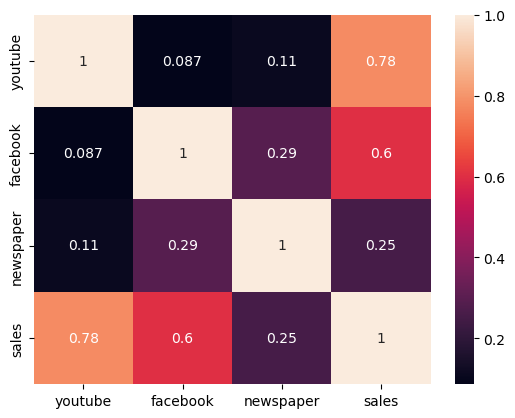

In [66]:
sns.heatmap(df.corr(),annot=True)
plt.show()

## Nota. 
```

Las relaciones entre la variable Sales con cada una de las variables explicativas es positiva (youtube: 0.78, facebook: 0.6, Newspaper: 0.25). Entre las variables explicativas  la relación es también positiva: relacion directa entre newspaper y facebook es 0.29 o entre newspaper y youtube: 0.11. La matriz de correlaciones es simetrica, es decir los varlores  que estan por encima de la diagonal principal (1's) son los mismos...porque? Porque la correlacion entre sales y youtube es la misma correlación entre youtube y sales.

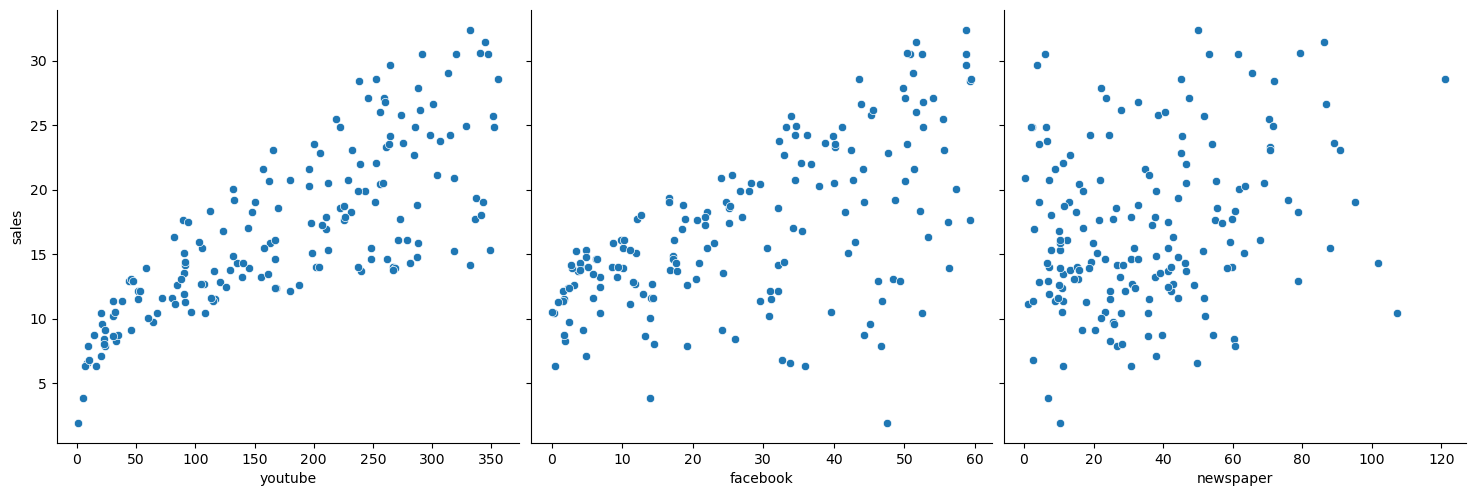

In [250]:
sns.pairplot(df1, x_vars=df1.columns[:3], y_vars=df1.columns[3], height=5)

```
Observamos una relación positiva entre sales y los distintos canales de marketing en los siguientes graficos

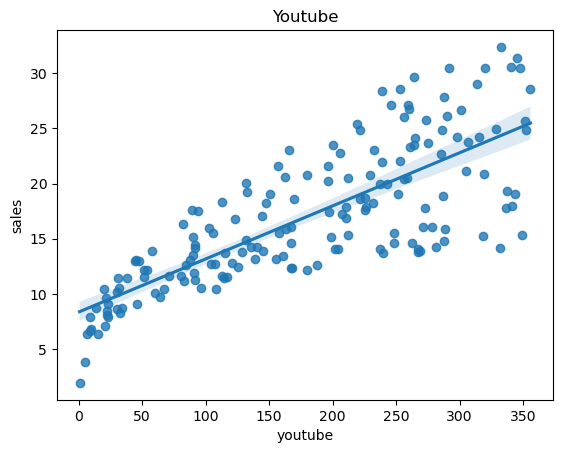

In [252]:
plt.title('Youtube')
sns.regplot(x=df1.youtube, y=df1.sales)
plt.show()

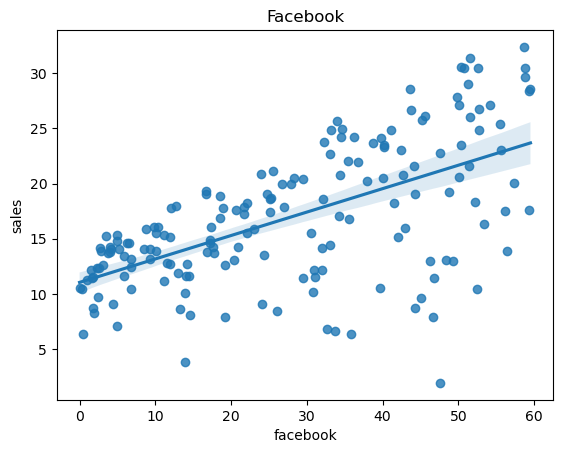

In [254]:
plt.title('Facebook')
sns.regplot(x=df1.facebook, y=df1.sales)
plt.show()

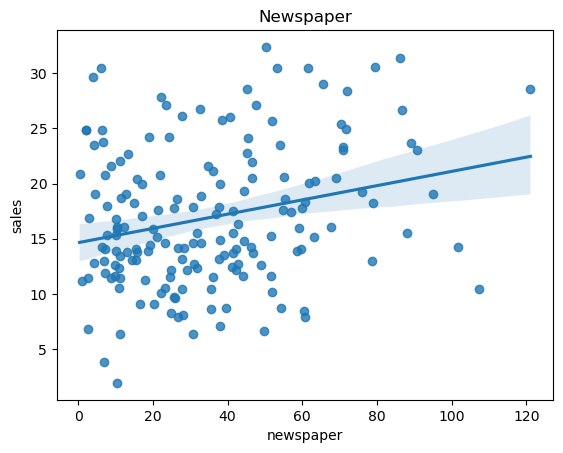

In [256]:
plt.title('Newspaper')
sns.regplot(x=df1.newspaper, y=df1.sales)
plt.show()

## División en conjunto de datos de entrenamiento y de prueba

In [258]:
# train test split
SEED = 42  
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=SEED)

## Preparando  nuestra  segunda regresión

In [261]:
X_train_adj = sm.add_constant(X_train) #En este primer modelo debo agregar un intercepto 
X_test_adj = sm.add_constant(X_test)
X_train_adj.head()

,const,youtube,facebook,newspaper
100,1.0,71.52,14.40,51.72
75,1.0,285.84,41.16,6.36
42,1.0,131.76,17.16,38.04
2,1.0,135.48,20.88,46.32
95,1.0,275.40,38.76,89.04


In [269]:
X_train_adj = X_train_adj.astype(float) #Segundo paso: me aseguro que todas sean tipo float
model= sm.OLS(endog=y_train,exog=X_train_adj) #Por ultimo creo mi modelo 
results =model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.907
Model:                            OLS   Adj. R-squared:                  0.905
Method:                 Least Squares   F-statistic:                     431.7
Date:                Wed, 08 Apr 2026   Prob (F-statistic):           5.13e-68
Time:                        17:41:19   Log-Likelihood:                -279.36
No. Observations:                 136   AIC:                             566.7
Df Residuals:                     132   BIC:                             578.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.7030      0.427      8.675      0.0

## Lectura de la salida de regresión

- Encontramos que las variables explicativas youtube y facebook tienen una relacion positiva con la variable dependiente Sales, dado que el signo de ambos estimadores
es positivo.  La variable newspaper tiene una relación inversa con la variable Sales.

- En cuanto a la significancia estadistica individual encontramos que las variable youtube y facebook son significativas individualmente pues los valores del
nivel de probabilidad (P>|t|) son menores al nivel de significancia escogido (5%, o 0.05).  Mientras tanto la variable newspaper no es estadisticamente significativa pues su nivel de probabilídad (0.094) es mayor que el nivel de significancia (0.05). Esto nos dice que las variables relevantes en el modelo son facebook y youtube y que la variable irrelevante es newspaper.

- Las variables son estadisticamente significativas en su conjunto pues es nivel de probabilidad del estadistico F (Prob (F-statistic))  es menor que el nivel de significancia escogido (5%).  



## Reestimo el modelo sin la variable newspaper

In [276]:
X = df1[["youtube", "facebook"]]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train_adj = sm.add_constant(X_train)
X_train_adj = X_train_adj.astype(float) #Segundo paso: me aseguro que todas sean tipo float
model= sm.OLS(endog=y_train,exog=X_train_adj) #Por ultimo creo mi modelo 
results =model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.907
Model:                            OLS   Adj. R-squared:                  0.906
Method:                 Least Squares   F-statistic:                     652.4
Date:                Wed, 08 Apr 2026   Prob (F-statistic):           1.78e-69
Time:                        18:38:44   Log-Likelihood:                -279.36
No. Observations:                 136   AIC:                             564.7
Df Residuals:                     133   BIC:                             573.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.7020      0.399      9.281      0.0

Concluimos que el mejor modelo es el que excluye a newspaper basandonos en los criterios de información.

## Pronosticando

In [278]:
modelo_regresion = LinearRegression()
modelo_regresion.fit(X_train,y_train)

modelo_regresion.predict(X_test) #predecimos con la muestra de test 

array([12.98003357, 25.05655057, 18.23961095, 20.63015975, 11.58859943,
        8.56517128, 13.34650944, 23.17369484, 12.02587238, 24.95814194,
       10.22539434, 13.42529889, 13.98349626, 11.03010539, 20.75747292,
       26.45354949, 28.93348411, 21.75776433, 21.24973646, 24.16491136,
       20.67827457,  9.84009911, 19.43563307, 18.2366762 , 14.2877248 ,
       26.10629785, 20.88101341, 10.57821479, 12.21786048, 23.1408031 ,
        7.00536346,  8.46431305, 16.60015374, 21.84149516, 18.13608054])

In [111]:
print("Intercepto:", modelo_regresion.intercept_)
print("Coeficientes:", modelo_regresion.coef_)

Intercepto: 3.7019666216006346
Coeficientes: [0.04418508 0.19446447]


In [280]:
final = X_test.copy()  #X_test es nuestra muestra de testeo.
final['prediccion'] = modelo_regresion.predict(X_test) #a la muestra de testeo agregue la columna prediccion
final.head()

,youtube,facebook,prediccion
101,0.84,47.52,12.980034
55,256.20,51.60,25.056551
56,231.84,22.08,18.239611
139,258.48,28.32,20.630160
157,167.40,2.52,11.588599


In [282]:
final['sales'] = y_test
final.head() #la calidad real la podemos mirar arriba con y_test.head().Son los datos de la muestra test en y

,youtube,facebook,prediccion,sales
101,0.84,47.52,12.980034,1.92
55,256.20,51.60,25.056551,26.04
56,231.84,22.08,18.239611,18.24
139,258.48,28.32,20.630160,20.52
157,167.40,2.52,11.588599,12.36


In [286]:
mae = mean_absolute_error(y_test, final['prediccion'])
mse = mean_squared_error(y_test, final['prediccion'])
rmse = np.sqrt(mse)

print(f'mae: {mae}')
print(f'mse: {mse}')
print(f'rmse: {rmse}')

mae: 1.4033502111399716
mse: 5.575635386602126
rmse: 2.361278337384673


```
El rmse nos dice que el pronostico falla en promedio en 2.36 mil dolares.

##### Nota. Si tienes dos modelos de pronostico calculas las metricas de pronostico y el que te de el menor valor de RMSE, es el modelo que mejor pronostica

## Validando los supuestos del modelo
```

Cuando hay heterocedasticidad (Var(εᵢ) no es constante) o autocorrelación (Cov(εᵢ, εⱼ) ≠ 0), el estimador MCO sigue siendo insesgado y consistente. Eso significa que los coeficientes β̂ siguen siendo válidos en promedio, y por tanto las predicciones puntuales ŷ = β̂₀ + β̂₁·pb + β̂₂·m también lo son.

Lo que sí se daña son los errores estándar. Las pruebas t, la prueba F, los p-valores y los intervalos de confianza ya no son confiables porque se basan en un σ² constante que ya no se cumple. En otras palabras, podrías concluir que β_pb es significativo cuando no lo es, o viceversa.

¿Cuándo sí afectan la capacidad predictiva?
En el caso de la autocorrelación, si los datos son de serie de tiempo (como el modelo de demanda de cerveza con 30 trimestres), hay una pérdida real de eficiencia: existiría un estimador alternativo —mínimos cuadrados generalizados (MCG)— que con la misma muestra produciría coeficientes con menor varianza, y por tanto predicciones más precisas. Además, si los errores siguen un patrón sistemático (AR(1), por ejemplo), puedes incorporar ese patrón al modelo y mejorar el pronóstico directamente.

## Test de heterocedasticidad: Test de White.
```
Para terminos de usar el modelo para pronosticar, la violacion del supuesto de homocedasticidad no es relevante.  Sin embargo para utilizarel modelo para 
fines explicativos, si es necesario validar los supuestos del modelo. El primero es ver si el modelo cumple con el supuesto de homocedasticidad.

Ho: Homocedasticidad
Ha: Heterocedasticidad


Se realiza el test de white y si el nivel de probabilidad de la prueba es menor a 0.05 se rechaza la hipotesis de homocedasticidad en favor de la hipotesis  alterna de heterocedasticdad, en cuyo caso hay que realizar una corrección para obtener errores estandar de los estimadores robustos a la heterocedaticidad.  Si el nivel  de probabilidad de la prueba es mayor a 0.05 (nivel de significancia con el que trabajamos), hay homocedasticidad, la Ho no se rechaza y el modelo cumple el supuesto.

In [120]:
white_test = het_white(results.resid, results.model.exog)

labels = ['Test Statistic', 'Test Statistic p-value', 'F-Statistic', 'F-Test p-value']
print(dict(zip(labels, white_test)))

{'Test Statistic': 75.34057834436183, 'Test Statistic p-value': 7.898401477459504e-15, 'F-Statistic': 32.292675787015774, 'F-Test p-value': 2.752009298603325e-21}


```
Se rechaza la hipotesis nula, luego hay que corregir la heterocedasticidad para obtener errores estandard de los estimadores robustos. En caso de heterocedasticidad es  urgente corregirla pues la inferencia estadistica no es valida pues los errores estandar de los estimadores en presencia de heterocedasticidad estan sesgados (no son los correctos)

## Correccion heterocedasticidad
```
Mantenemos  los coeficientes y usamos los  errores estándar robustos. No cambia los coeficientes, solo los errores estándar / p-values para inferencia válida.

In [122]:
# HC0, HC1, HC2, HC3, HC4 disponibles
robust_hc3 = results.get_robustcov_results(cov_type='HC3')
print(robust_hc3.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.907
Model:                            OLS   Adj. R-squared:                  0.906
Method:                 Least Squares   F-statistic:                     561.9
Date:                Fri, 03 Oct 2025   Prob (F-statistic):           1.37e-65
Time:                        21:30:12   Log-Likelihood:                -279.36
No. Observations:                 136   AIC:                             564.7
Df Residuals:                     133   BIC:                             573.5
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.7020      0.456      8.117      0.0

```
Nota: Los estimadores no cambian mas si los errores estandar. La inferencia estadistica individual debe hacerse con esa salida del modelo de regresión. En caso de que hubiese heterocedaticidad y les pidiera hacer inferencia estaditica individual tendrian que hacerlo con los valores de esta tabla.  Los estimadores no cambian asi que la interpretacion de los estimadores sigue siendo la misma que en el modelo de regresión sin corregir. Para pronosticar la violacion del supuesto de heterocedaticdad no es relevante.

## Test de autocorrelacion: Test de Breusch–Godfrey

Para detectar autocorrelación de orden superior

In [256]:
# Test de Breusch–Godfrey
bg_test = acorr_breusch_godfrey(results, nlags=4)  # por ejemplo, hasta 4 rezagos
labels = ['LM Stat', 'LM p-value', 'F Stat', 'F p-value']
print(dict(zip(labels, bg_test)))

{'LM Stat': 7.340708792058606, 'LM p-value': 0.11894198337393143, 'F Stat': 1.8400370180904428, 'F p-value': 0.12505825803897194}


```
Para terminos de usar el modelo para pronosticar, la violacion del supuesto de no autocorrelacion no es relevante.  Sin embargo para utiliza rel modelo para 
fines explicativos, si es necesario validar los supuestos del modelo. El primero es ver si el modelo cumple con el supuesto de no autocorrelacion.

Ho: No autocorrelacion
Ha: Autocorrelacion

Se realiza el test de Breush-Godrey y si el nivel de probabilidad de la prueba es menor a 0.05 se rechaza la hipotesis de no autocorrelacion en favor de la hipotesis 
alterna de autocorrelacion, en cuyo caso hay que realizar una corrección para obtener errores estandar de los estimadores robustos a la autocorrelacion.  Si el nivel 
de probabilidad de la prueba es mayor a 0.05 (nivel de significancia con el que trabajamos), hay No hay  autocorrelacion, la Ho no se rechaza y el modelo cumple el supuesto.

```
En este caso la hipotesis nula no se rechaza, el modelo cumple con el supuesto de No autocorrelacion.

```
Si tuvieramos que corregir (que no es nuestro caso) usariamos el siguiente codigo.

In [302]:
# Estimar modelo OLS
#model = sm.OLS(endog=y_train, exog=X_train_adj)
#results = model.fit()

# Newey–West (HAC) pasando maxlags directamente
#lags = 4
#model_hac = results.get_robustcov_results(cov_type='HAC', maxlags=lags)

#print(model_hac.summary())


## Ejercicio 2

This is the historical data that covers sales from 2010-02-05 to 2012-11-01, in the file Walmart_Store_sales. Within this file you will find the following fields:\

- Store - the store number
- Date - the week of sales
- Weekly_Sales - sales for the given store
- Holiday_Flag - whether the week is a special holiday week 1 – Holiday week 0 – Non-holiday week
- Temperature - Temperature on the day of sale
- Fuel_Price - Cost of fuel in the region
- CPI – Prevailing consumer price index
- Unemployment - Prevailing unemployment rate
- Holiday Events<br /> Super Bowl: 12-Feb-10, 11-Feb-11, 10-Feb-12, 8-Feb-13<br /> Labour Day: 10-Sep-10, 9-Sep-11, 7-Sep-12, 6-Sep-13<br /> Thanksgiving: 26-Nov-10, 25-Nov-11, 23-Nov-12, 29-Nov-13<br /> Christmas: 31-Dec-10, 30-Dec-11, 28-Dec-12, 27-Dec-13

In [ ]:
# Este codigo solo debe correrse en google colab
from google.colab import files

# Abrir ventana para seleccionar el archivo
uploaded = files.upload()

In [606]:
df=pd.read_csv('Walmart.csv')

In [608]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [610]:
#handling date in dataframe
df['Date'] = pd.to_datetime(df['Date'],format="%d-%m-%Y")

In [612]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


In [614]:
df.dtypes

Store                    int64
Date            datetime64[ns]
Weekly_Sales           float64
Holiday_Flag             int64
Temperature            float64
Fuel_Price             float64
CPI                    float64
Unemployment           float64
dtype: object

In [616]:
#Verificando el día del cálculo de ventas semanales
df["Day"] = df['Date'].dt.day_name()
#all the days are friday only
df['Day'].unique()

array(['Friday'], dtype=object)

- df['Date'] → selecciona la columna Date de tu DataFrame (debe estar en formato de fecha datetime64).
- .dt → accede a los métodos de fechas de pandas.
- day_name() → convierte cada fecha en el nombre del día de la semana (por ejemplo, "Monday", "Tuesday", etc.).
- df["Day"]  → crea una nueva columna llamada Day con esos nombres de día.

In [619]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Day
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,Friday
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,Friday
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,Friday
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,Friday
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,Friday


In [621]:
#lets drop the date colum
df = df.drop(['Date', "Day", "Store"],axis=1)

In [623]:
df.head()

,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1643690.90,0,42.31,2.572,211.096358,8.106
1,1641957.44,1,38.51,2.548,211.242170,8.106
2,1611968.17,0,39.93,2.514,211.289143,8.106
3,1409727.59,0,46.63,2.561,211.319643,8.106
4,1554806.68,0,46.50,2.625,211.350143,8.106


In [625]:
X=df.drop(['Weekly_Sales'],axis=1) # variables explicativas
y=df['Weekly_Sales'] # variable dependiente

In [627]:
# train test split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [629]:
X_train_adj = sm.add_constant(X_train) #En este primer modelo debo agregar un intercepto 
X_test_adj = sm.add_constant(X_test)
X_train_adj.head()

,const,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
1033,1.0,0,75.32,2.582,214.878556,6.315
915,1.0,0,20.70,3.372,192.058484,8.818
5903,1.0,0,61.24,3.130,126.546161,9.003
2083,1.0,0,69.19,3.906,136.213613,7.806
5943,1.0,0,87.40,3.743,129.240581,8.257


In [650]:
X_train_adj = X_train_adj.astype(float) #Segundo paso: me aseguro que todas sean tipo float
model= sm.OLS(endog=y_train,exog=X_train_adj) #Por ultimo creo mi modelo 
results =model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:           Weekly_Sales   R-squared:                       0.027
Model:                            OLS   Adj. R-squared:                  0.026
Method:                 Least Squares   F-statistic:                     28.80
Date:                Thu, 09 Apr 2026   Prob (F-statistic):           6.54e-29
Time:                        11:12:02   Log-Likelihood:                -75403.
No. Observations:                5148   AIC:                         1.508e+05
Df Residuals:                    5142   BIC:                         1.509e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          1.77e+06   8.88e+04     19.934   

In [654]:
# Predicciones con statsmodels
y_pred = results.predict(X_test_adj)
print(y_pred)

2436    1.072158e+06
3361    1.073252e+06
233     9.853152e+05
3667    1.120597e+06
5011    9.652472e+05
            ...     
2600    1.100394e+06
6308    9.872625e+05
6292    1.006896e+06
151     9.777170e+05
2344    1.180995e+06
Length: 1287, dtype: float64


In [658]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'mae: {mae}')
print(f'mse: {mse}')
print(f'rmse: {rmse}')

mae: 475432.5329588254
mse: 316554511405.1149
rmse: 562631.7724810028


## Eliminamos las variables no significativas

Opción 1 — Backward Elimination automática
```
def backward_elimination(X, y, significance=0.05):
    cols = list(X.columns)
    while True:
        X_adj = sm.add_constant(X[cols]).astype(float)
        p_values = sm.OLS(y, X_adj).fit().pvalues.drop("const")
        max_p = p_values.max()
        if max_p > significance:
            cols.remove(p_values.idxmax())  # elimina la menos significativa
            print(f"Eliminando: {p_values.idxmax()} (p={max_p:.3f})")
        else:
            break
    return cols

cols_finales = backward_elimination(X_train, y_train)
print("Variables finales:", cols_finales)

In [660]:
# Eliminar las variables no significativas
cols_significativas = ["Holiday_Flag", "CPI", "Unemployment"]

X_train_adj2 = sm.add_constant(X_train[cols_significativas]).astype(float)
X_test_adj2  = sm.add_constant(X_test[cols_significativas]).astype(float)

model2 = sm.OLS(endog=y_train, exog=X_train_adj2)
results2 = model2.fit()
print(results2.summary())

                            OLS Regression Results                            
Dep. Variable:           Weekly_Sales   R-squared:                       0.027
Model:                            OLS   Adj. R-squared:                  0.026
Method:                 Least Squares   F-statistic:                     46.93
Date:                Thu, 09 Apr 2026   Prob (F-statistic):           6.51e-30
Time:                        11:17:28   Log-Likelihood:                -75404.
No. Observations:                5148   AIC:                         1.508e+05
Df Residuals:                    5144   BIC:                         1.508e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         1.677e+06   5.71e+04     29.378   

## Pronostico

In [662]:
# Predicciones con statsmodels
y_pred = results2.predict(X_test_adj2)
print(y_pred)

2436    1.051184e+06
3361    1.089247e+06
233     9.874111e+05
3667    1.114449e+06
5011    9.503038e+05
            ...     
2600    1.098643e+06
6308    9.813151e+05
6292    9.774879e+05
151     9.651493e+05
2344    1.160441e+06
Length: 1287, dtype: float64


In [664]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'mae: {mae}')
print(f'mse: {mse}')
print(f'rmse: {rmse}')

mae: 474980.1384198102
mse: 316684430984.05786
rmse: 562747.217659988


## Porque da ligeramente menor el RMSE en el modelo que conserva las variables pese  no ser significativas?
```

Significancia estadística ≠ poder predictivo

1. El p-value mide si una variable es estadísticamente distinguible de cero en la muestra, pero no mide directamente cuánto ayuda a predecir fuera de muestra. Una variable puede ser "no significativa" y aún así reducir el error de predicción.

2. El test set es pequeño y aleatorio
Con random_state=42 se obtuvo una partición específica. En esa partición particular, puede que Temperature y Fuel_Price tengan una relación con Weekly_Sales que el modelo aprovecha, aunque en la población general no sea significativa.

En la práctica

Si la diferencia de RMSE es pequeña, siempre debe priorizarse el modelo reducido porque:

Es más parsimonioso
Más interpretable
Más generalizable a nuevos datos
Evita incluir variables cuya relación puede ser espuria

La regla general es usar criterios como AIC o BIC (que ya aparecen en tu summary de statsmodels) para comparar modelos — penalizan la complejidad y son más confiables que comparar RMSE en un solo test set.

## Validando los supuestos del modelo

## Test de heterocedasticidad: Test de White.

Vamos  a realizar un test de heterocedasticidad de White para probar estas hipostesis:

#### Ho: Homocedasticidad
#### Ha: Heterocedasticidad

In [607]:
white_test = het_white(results.resid, results.model.exog)

labels = ['Test Statistic', 'Test Statistic p-value', 'F-Statistic', 'F-Test p-value']
print(dict(zip(labels, white_test)))

{'Test Statistic': 108.19287647970243, 'Test Statistic p-value': 8.950944815635798e-20, 'F-Statistic': 13.790289454589894, 'F-Test p-value': 5.51109758505358e-20}


El nivel de probabilidad es menor que 0.05, luego rechazo Ho y hay que corregir el problema.

## Correccion heterocedasticidad

Mantenemos los coeficientes y usamos los errores estándar robustos. No cambia los coeficientes, solo los errores estándar / p-values para inferencia válida.

In [611]:
# HC0, HC1, HC2, HC3, HC4 disponibles
robust_hc3 = results.get_robustcov_results(cov_type='HC3')
print(robust_hc3.summary())

                            OLS Regression Results                            
Dep. Variable:           Weekly_Sales   R-squared:                       0.027
Model:                            OLS   Adj. R-squared:                  0.026
Method:                 Least Squares   F-statistic:                     49.48
Date:                Tue, 24 Feb 2026   Prob (F-statistic):           1.62e-31
Time:                        15:13:52   Log-Likelihood:                -75404.
No. Observations:                5148   AIC:                         1.508e+05
Df Residuals:                    5144   BIC:                         1.508e+05
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         1.677e+06   5.84e+04     28.711   

Esta salida es la que debe anexarse en los inforrmes cuando se utilizan los modelos de regresión para fines explicativos.  La inferencia estadistica debe realizarse
con estos resultados.  Miremos ahora si hay Autocorrelacion:

## Validando los supuestos del modelo

## Test de Autocorrelacion: Test de Breuch-Godfrey.

Vamos  a realizar un test de heterocedasticidad de White para probar estas hipostesis:

#### Ho: No autocorrelacion
#### Ha: Autororrelacion

In [615]:
# Test de Breusch–Godfrey
bg_test = acorr_breusch_godfrey(results, nlags=4)  # por ejemplo, hasta 4 rezagos
labels = ['LM Stat', 'LM p-value', 'F Stat', 'F p-value']
print(dict(zip(labels, bg_test)))

{'LM Stat': 2.590155027506989, 'LM p-value': 0.6285681049306786, 'F Stat': 0.6468579395272288, 'F p-value': 0.6290773657465638}


El valor P es mayor que el nivel de significancia escogido (0.62>0.05).  Ho no es rechazada, no hay autocorrelacion.